# Worked example capstone: who will be a high-value customer next quarter?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/11-capstone/02-capstone/example/example.ipynb)

This is a compact, complete capstone, written so you can compare your own against it. It follows the brief in [11.2](../README.md) section by section. Read the [README](README.md) first for the summary, then come here for the work.

It reuses what you built in the course (the cleaning from 01.5, the time-split customer table from 01.9, pipelines from 04.8, cross-validation from 04.7, model comparison from 05.10). Nothing here is new; the point is putting it together and writing it up.

## 1. Problem framing

**User.** ShopWave's marketing team.

**Decision.** Every quarter they print a premium catalogue and post it to a limited number of customers. Each one costs about £3. They want it to go to the customers who will spend the most in the coming quarter.

**Target.** `high_value = 1` if the customer spends **£500 or more in the 3 months after the cut-off date**. Chosen with marketing: £500 is roughly the spend at which a catalogue reliably pays for itself.

**Unit.** One registered customer, as of a cut-off date. Features use only orders before the cut-off; the target uses only orders after it (the fence from 00.5 and 04.2).

**Baseline.** What marketing does today: send it to everyone who spent £500 or more in the *last* 90 days.

**Metric.** ROC-AUC to compare models, and **precision among the top 500** customers, because 500 catalogues is the budget.

## 2. Data: load and clean

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import sys, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]                      # no cancellations
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)]                    # no returns or free lines
sales = sales.dropna(subset=["Customer ID"]).drop_duplicates()                   # registered customers only
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])
print(f"{len(raw):,} raw rows -> {len(sales):,} clean rows, "
      f"{sales['InvoiceDate'].min():%Y-%m-%d} to {sales['InvoiceDate'].max():%Y-%m-%d}")

541,910 raw rows -> 392,693 clean rows, 2010-12-01 to 2011-12-09


## 3. The customer table, built the same way at two dates

A **time-based split** is the honest one here (04.1): the model is trained on what was known on 1 June 2011 and tested as if it were 1 September 2011. The test customers' futures (September to November) were never seen in training.

In [2]:
THRESHOLD = 500
FEATURES = ["orders", "spend", "products", "tenure_days", "days_since_last",
            "avg_order", "spend_90d", "orders_90d", "is_uk"]

def customer_table(cutoff):
    cutoff = pd.Timestamp(cutoff)
    past = sales[sales["InvoiceDate"] < cutoff]
    future = sales[(sales["InvoiceDate"] >= cutoff) &
                   (sales["InvoiceDate"] < cutoff + pd.DateOffset(months=3))]
    recent = past[past["InvoiceDate"] >= cutoff - pd.Timedelta(days=90)]
    c = past.groupby("Customer ID").agg(
        orders=("Invoice", "nunique"), spend=("Revenue", "sum"), products=("StockCode", "nunique"),
        first=("InvoiceDate", "min"), last=("InvoiceDate", "max"), country=("Country", "first"))
    c["tenure_days"] = (cutoff - c["first"]).dt.days
    c["days_since_last"] = (cutoff - c["last"]).dt.days
    c["avg_order"] = c["spend"] / c["orders"]
    c["spend_90d"] = recent.groupby("Customer ID")["Revenue"].sum().reindex(c.index).fillna(0)
    c["orders_90d"] = recent.groupby("Customer ID")["Invoice"].nunique().reindex(c.index).fillna(0)
    c["is_uk"] = (c["country"] == "United Kingdom").astype(int)
    c["future_spend"] = future.groupby("Customer ID")["Revenue"].sum().reindex(c.index).fillna(0)
    c["high_value"] = (c["future_spend"] >= THRESHOLD).astype(int)
    return c.drop(columns=["first", "last", "country"])

In [3]:
train = customer_table("2011-06-01")
test = customer_table("2011-09-01")
for name, t in [("train (cut-off 1 Jun)", train), ("test  (cut-off 1 Sep)", test)]:
    print(f"{name}: {len(t):,} customers, high-value rate {t['high_value'].mean():.1%}")

train (cut-off 1 Jun): 2,718 customers, high-value rate 24.4%
test  (cut-off 1 Sep): 3,317 customers, high-value rate 32.0%


## 4. Exploratory analysis

Three things to check before modelling (01.9): how rare the target is, whether it drifts, and whether the obvious feature is as good as it looks.

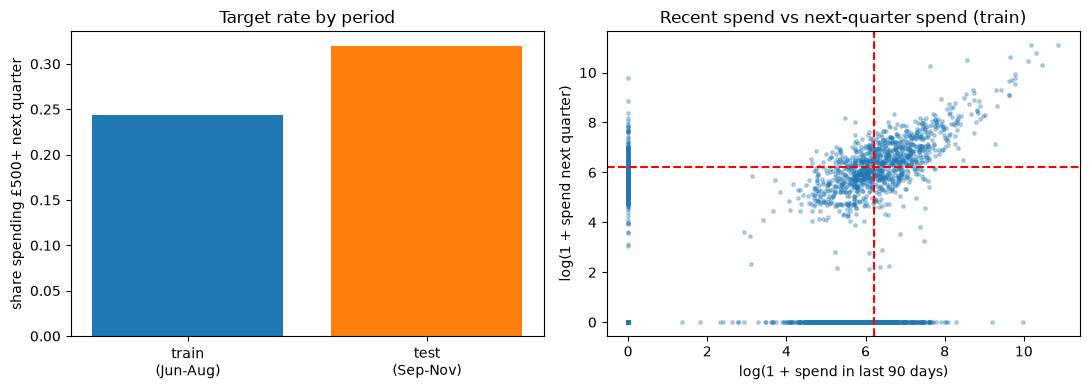

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(["train\n(Jun-Aug)", "test\n(Sep-Nov)"],
            [train["high_value"].mean(), test["high_value"].mean()], color=["tab:blue", "tab:orange"])
axes[0].set_ylabel("share spending £500+ next quarter"); axes[0].set_title("Target rate by period")
axes[1].scatter(np.log1p(train["spend_90d"]), np.log1p(train["future_spend"]), s=6, alpha=.3)
axes[1].axvline(np.log1p(THRESHOLD), color="red", ls="--"); axes[1].axhline(np.log1p(THRESHOLD), color="red", ls="--")
axes[1].set_xlabel("log(1 + spend in last 90 days)"); axes[1].set_ylabel("log(1 + spend next quarter)")
axes[1].set_title("Recent spend vs next-quarter spend (train)")
plt.tight_layout(); plt.show()

In [5]:
print("Customers with zero spend in the last 90 days (train):",
      f"{(train['spend_90d'] == 0).mean():.1%}")
print("...of whom became high-value next quarter:",
      f"{train.loc[train['spend_90d'] == 0, 'high_value'].mean():.1%}")
train[FEATURES].describe().T[["mean", "50%", "max"]].round(1)

Customers with zero spend in the last 90 days (train): 27.9%
...of whom became high-value next quarter: 10.0%


,mean,50%,max
orders,2.7,2.0,86.0
spend,1223.1,475.1,110713.1
products,41.7,26.0,881.0
tenure_days,111.4,117.0,181.0
days_since_last,63.0,49.0,181.0
avg_order,406.5,290.9,77183.6
spend_90d,624.5,270.0,52847.1
orders_90d,1.4,1.0,42.0
is_uk,0.9,1.0,1.0


**What EDA told us.**

- The target rate rises from training to test (the autumn quarter before Christmas, as in Module 07). Any probability the model outputs will be *calibrated to summer*. Ranking customers still works; absolute probabilities will be too low. This goes in the monitoring plan.
- Recent spend predicts future spend, but the cloud is wide: plenty of customers above the line fall below it next quarter, and some with no recent spend come back big.
- Every money column is heavily skewed, so the linear model gets a log transform (04.6).

## 5. Baselines

In [6]:
from sklearn.metrics import roc_auc_score, precision_score, recall_score

y_train, y_test = train["high_value"], test["high_value"]
rule = (test["spend_90d"] >= THRESHOLD).astype(int)
print(f"Majority class ('nobody is high-value') accuracy: {1 - y_test.mean():.1%}")
print(f"Marketing's rule (spend_90d >= £{THRESHOLD}): flags {rule.sum():,} customers, "
      f"precision {precision_score(y_test, rule):.3f}, recall {recall_score(y_test, rule):.3f}")
print(f"Ranking by spend_90d alone, test AUC: {roc_auc_score(y_test, test['spend_90d']):.3f}")

Majority class ('nobody is high-value') accuracy: 68.0%
Marketing's rule (spend_90d >= £500): flags 822 customers, precision 0.672, recall 0.520
Ranking by spend_90d alone, test AUC: 0.744


## 6. Two modelling approaches, compared with cross-validation on the training table only

- **Logistic regression** on log-transformed, scaled features (03.4, 04.8).
- **LightGBM** with conservative settings (05.4).

The test table is not touched in this section.

In [7]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier

models = {
    "logistic": make_pipeline(FunctionTransformer(np.log1p), StandardScaler(),
                              LogisticRegression(max_iter=2000)),
    "lightgbm": LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=8,
                               min_child_samples=30, verbose=-1, random_state=42),
}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
cv_scores = {name: cross_val_score(m, train[FEATURES], y_train, cv=cv, scoring="roc_auc")
             for name, m in models.items()}
pd.DataFrame({n: [s.mean(), s.std()] for n, s in cv_scores.items()}, index=["CV AUC mean", "CV AUC std"]).round(3)

,logistic,lightgbm
CV AUC mean,0.848,0.847
CV AUC std,0.027,0.026


The two are within a fraction of one standard deviation of each other. Following 05.10, when scores tie, choose the simpler, more explainable model: **logistic regression**. LightGBM is still scored on the test set below, for the record, not for selection. (On the test set it does slightly better in the top 500 and slightly worse on AUC: another tie. Choosing it *because* of a test-set number would be tuning on the test set.)

## 7. The test set, used once

In [8]:
from sklearn.metrics import average_precision_score

def top_k_precision(y, p, k=500):
    top = np.argsort(-np.asarray(p))[:k]
    return np.asarray(y)[top].mean()

rows = {}
for name, m in models.items():
    p = m.fit(train[FEATURES], y_train).predict_proba(test[FEATURES])[:, 1]
    rows[name] = [roc_auc_score(y_test, p), average_precision_score(y_test, p), top_k_precision(y_test, p)]
rows["spend_90d ranking"] = [roc_auc_score(y_test, test["spend_90d"]),
                             average_precision_score(y_test, test["spend_90d"]),
                             top_k_precision(y_test, test["spend_90d"])]
results = pd.DataFrame(rows, index=["test AUC", "average precision", "precision @ top 500"]).T.round(3)
results

,test AUC,average precision,precision @ top 500
logistic,0.815,0.716,0.810
lightgbm,0.808,0.709,0.818
spend_90d ranking,0.744,0.630,0.746


In [9]:
p_test = models["logistic"].predict_proba(test[FEATURES])[:, 1]
top500 = np.argsort(-p_test)[:500]
hits_model = int(y_test.iloc[top500].sum())
rule_rank = np.argsort(-test["spend_90d"].values)[:500]
hits_rule = int(y_test.iloc[rule_rank].sum())
print(f"Catalogues to the model's top 500: {hits_model} reach a high-value customer")
print(f"Catalogues to the top 500 by recent spend: {hits_rule}")
print(f"Difference: {hits_model - hits_rule:+d} high-value customers reached for the same £1,500")

Catalogues to the model's top 500: 405 reach a high-value customer
Catalogues to the top 500 by recent spend: 373
Difference: +32 high-value customers reached for the same £1,500


## 8. Error analysis

In [10]:
test_scored = test.assign(p=p_test, in_top500=0)
test_scored.iloc[top500, test_scored.columns.get_loc("in_top500")] = 1
missed = test_scored[(test_scored["high_value"] == 1) & (test_scored["in_top500"] == 0)]
wasted = test_scored[(test_scored["high_value"] == 0) & (test_scored["in_top500"] == 1)]
hit = test_scored[(test_scored["high_value"] == 1) & (test_scored["in_top500"] == 1)]
cols = ["orders", "spend_90d", "days_since_last", "tenure_days", "future_spend"]
pd.DataFrame({"hits (top 500, high-value)": hit[cols].median(),
              "wasted (top 500, not high-value)": wasted[cols].median(),
              "missed (high-value, not in top 500)": missed[cols].median()}).round(0)

,"hits (top 500, high-value)","wasted (top 500, not high-value)","missed (high-value, not in top 500)"
orders,9.0,6.0,2.0
spend_90d,1309.0,977.0,289.0
days_since_last,16.0,28.0,67.0
tenure_days,260.0,232.0,186.0
future_spend,1733.0,3.0,863.0


In [11]:
print(f"Missed high-value customers: {len(missed):,}")
print(f"  of whom bought nothing in the last 90 days: {(missed['spend_90d'] == 0).mean():.0%}")
print(f"  of whom have only one order ever:          {(missed['orders'] == 1).mean():.0%}")
print(f"Wasted catalogues: {len(wasted)}; their median next-quarter spend: £{wasted['future_spend'].median():,.0f}")

Missed high-value customers: 656
  of whom bought nothing in the last 90 days: 37%
  of whom have only one order ever:          30%
Wasted catalogues: 95; their median next-quarter spend: £3


**What the errors say.**

- **Wasted catalogues (95 of 500)** went to customers who looked like the hits (several orders, recent purchases, high spend) but then bought almost nothing next quarter: median £3. On the data available on 1 September they are indistinguishable from good customers; they simply did not come back this time.
- **Missed high-value customers (656)** are the bigger group. They have fewer orders and lower recent spend than the hits; about a third bought nothing in the last 90 days and about a third have ordered only once. Many of them are customers whose big Christmas order could not be foreseen from their history.
- Neither group points to a modelling bug. Catching more of the missed customers would need **new information** (browsing, email engagement, wholesale status), not a cleverer algorithm. That is the main recommendation for the next iteration.

## 9. Explaining the model

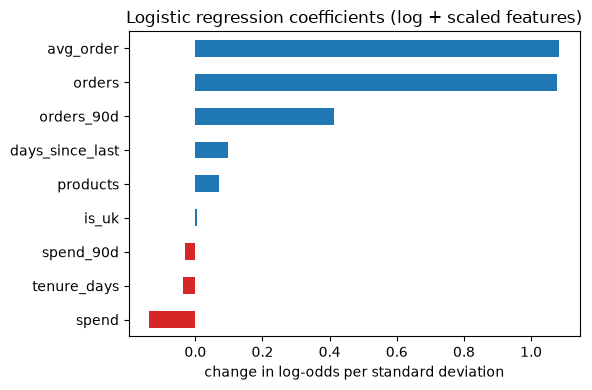

spend             -0.14
tenure_days       -0.04
spend_90d         -0.03
is_uk              0.00
products           0.07
days_since_last    0.10
orders_90d         0.41
orders             1.08
avg_order          1.08
dtype: float64

In [12]:
lr = models["logistic"].named_steps["logisticregression"]
coef = pd.Series(lr.coef_[0], index=FEATURES).sort_values()
coef.plot.barh(figsize=(6, 4), color=["tab:red" if v < 0 else "tab:blue" for v in coef])
plt.title("Logistic regression coefficients (log + scaled features)")
plt.xlabel("change in log-odds per standard deviation"); plt.tight_layout(); plt.show()
coef.round(2)

In [13]:
from sklearn.inspection import permutation_importance
perm = permutation_importance(models["logistic"], test[FEATURES], y_test, scoring="roc_auc",
                              n_repeats=10, random_state=42)
pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False).round(3)

orders             0.153
avg_order          0.109
orders_90d         0.011
days_since_last    0.002
products           0.001
spend              0.001
tenure_days        0.000
spend_90d          0.000
is_uk              0.000
dtype: float64

Coefficients describe what the model does with each feature *holding the others fixed* (02.5); permutation importance says how much test AUC drops when a feature is scrambled (05.8). Both agree: **how many orders a customer has placed and how big their average order is** drive the prediction. Recent spend and recency add little once those two are known, and some coefficients (total `spend`, slightly negative) only make sense as corrections among correlated features, so do not read them on their own.

## 10. Saving the model and scoring a new customer

In [14]:
import joblib
from pathlib import Path

models_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir()) / "models"
models_dir.mkdir(exist_ok=True)
auc = results.loc["logistic", "test AUC"]
path = models_dir / f"high_value_logistic_auc{auc:.3f}.joblib"
joblib.dump({"model": models["logistic"], "features": FEATURES, "threshold_gbp": THRESHOLD,
             "trained_on_cutoff": "2011-06-01"}, path)
print("saved", path.name)

saved high_value_logistic_auc0.815.joblib


In [15]:
bundle = joblib.load(path)
new_customer = pd.DataFrame([{"orders": 4, "spend": 1200, "products": 60, "tenure_days": 200,
                              "days_since_last": 20, "avg_order": 300, "spend_90d": 650,
                              "orders_90d": 2, "is_uk": 1}])
p_new = bundle["model"].predict_proba(new_customer[bundle["features"]])[0, 1]
print(f"Probability this customer spends £{bundle['threshold_gbp']}+ next quarter: {p_new:.2f}")

Probability this customer spends £500+ next quarter: 0.41


## 11. Monitoring plan

- **Every quarter, after the quarter ends:** compute precision in the top 500 against what actually happened. Alert if it falls below the recent-spend rule's.
- **Before every scoring run:** compare the feature distributions with the training table (10.6). Spend features drift with season.
- **Probability calibration:** the training quarter had a 24% high-value rate, the autumn quarter 32%. Use the model for **ranking only**, or recalibrate on the same quarter of the previous year.
- **Retrain** each quarter on the most recent complete quarter, and compare against the current model on the same holdout before replacing it.

## 12. Conclusion

See the [README](README.md) for the one-page summary and the [model card](model_card.md) for the details a reviewer will ask about.